# DNN Assignment 2 — Problem 2: Transformer from scratch

**Student:** RAKSHANTHA M · **Student ID:** 2026AK05368

- Cells marked **`YOUR CODE — from scratch`** (attention, positional encoding, multi-head attention, encoder block) must be written by you. `nn.MultiheadAttention` and `nn.Transformer*` are used **only** inside the test cells, to check your code.
- Unit tests are `assert` cells directly after the code they test.
- Run with *Kernel → Restart and Run All*. Results are appended to `../results.csv` after every run.
- `QUICK = True` gives a few-minute smoke test of every cell.

## 0. Configuration (fill in once)

**ASSUMPTIONS:**
The variants table referred to under “Individualisation” was not included in the released assignment, so I used D_MODEL 128 and seeds 0, 1, 2.

In [1]:
STUDENT_ID = "2026AK05368"
D_MODEL    = 128             # <-- model width from YOUR row of the variants table (brief: d = 128 for the LM)
SEEDS      = [0, 1, 2]       # <-- your three seeds
QUICK      = False
RUN_BONUS  = True            # optional stretch (bonus): LSTM vs Transformer on the character task

# Task A (HAR encoder) — same budget as Problem 1
D_HAR, HEADS_HAR, LAYERS_HAR, PATCH = 64, 4, 2, 8
EPOCHS_HAR = 2 if QUICK else 30
BATCH_HAR  = 64

# Task B (character LM)
CTX, HEADS, LAYERS, DROPOUT = 128, 4, 4, 0.1
BATCH_LM   = 64
LM_ITERS   = 100 if QUICK else 5000      # main model
ABL_ITERS  = 60  if QUICK else 1500      # each ablation run (heads, no-mask)
EVAL_EVERY = 20  if QUICK else 250
EVAL_BATCHES = 5 if QUICK else 50
LR = 1e-3
TOP_K = 20

In [2]:
import os, time, math, random, zipfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
DATA = "data";   os.makedirs(DATA, exist_ok=True)
RESULTS_CSV = "../results.csv"
print("device:", DEVICE, "| torch", torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse","params",
        "sec_per_epoch","val_loss_nats","bits_per_char","notes"]
def log_result(**kw):
    bad = set(kw) - set(COLS); assert not bad, bad
    pd.DataFrame([{c: kw.get(c, "") for c in COLS}]).to_csv(RESULTS_CSV, mode="a", index=False,
                                                            header=not os.path.exists(RESULTS_CSV))
def mean_std(x):
    x = np.asarray(x, dtype=float); return f"{x.mean():.4f} ± {x.std(ddof=1) if len(x) > 1 else 0:.4f}"
if os.path.exists(RESULTS_CSV):
    _df = pd.read_csv(RESULTS_CSV); _df[_df.problem != "P2"].to_csv(RESULTS_CSV, index=False)
n_params = lambda m: sum(p.numel() for p in m.parameters())

device: cuda | torch 2.14.1+cu130


## Task 1 — Scaled dot-product attention (10)
**Interface:** `scaled_dot_product_attention(q, k, v, mask=None)` with `q: (..., T_q, d_k)`, `k: (..., T_k, d_k)`, `v: (..., T_k, d_v)`, and an optional **boolean** `mask` broadcastable to `(..., T_q, T_k)` where `True` = may attend. Returns `(output (..., T_q, d_v), weights (..., T_q, T_k))`.

In [3]:
# ===================== YOUR CODE — from scratch =====================
import math

def scaled_dot_product_attention(q, k, v, mask=None):
    # q: (..., Lq, d_k), k: (..., Lk, d_k), v: (..., Lk, d_v)
    # mask: broadcastable to (..., Lq, Lk); True/1 = may attend, False/0 = blocked
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., Lq, Lk)
    if mask is not None:
        scores = scores.masked_fill(~mask.bool(), float("-inf"))
    weights = torch.softmax(scores, dim=-1)                     # each row sums to 1
    return weights @ v, weights                                 # (..., Lq, d_v), (..., Lq, Lk)
# ====================================================================

In [4]:
torch.manual_seed(0)
q, k, v = torch.randn(2, 3, 5, 8), torch.randn(2, 3, 7, 8), torch.randn(2, 3, 7, 4)
out, w = scaled_dot_product_attention(q, k, v)
assert out.shape == (2, 3, 5, 4) and w.shape == (2, 3, 5, 7)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 5), atol=1e-6)                        # rows sum to 1
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v), atol=1e-5)          # matches PyTorch

q, k, v = torch.randn(2, 3, 6, 8), torch.randn(2, 3, 6, 8), torch.randn(2, 3, 6, 8)
causal = torch.tril(torch.ones(6, 6, dtype=torch.bool))
out, w = scaled_dot_product_attention(q, k, v, mask=causal)
assert (w.masked_select(~causal) == 0).all()                                            # no weight on the future
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 6), atol=1e-6)
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v, attn_mask=causal), atol=1e-5)
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v, is_causal=True), atol=1e-5)
torch.manual_seed(0)
q1, k1, v1 = torch.randn(2, 3, 5, 8), torch.randn(2, 3, 7, 8), torch.randn(2, 3, 7, 4)
o1, w1 = scaled_dot_product_attention(q1, k1, v1)
print(f"rows of weights sum to 1:          max |row sum - 1| = {(w1.sum(-1) - 1).abs().max():.2e}")
print(f"matches F.scaled_dot_product_attention: max |diff| = {(o1 - F.scaled_dot_product_attention(q1, k1, v1)).abs().max():.2e} (tolerance 1e-5)")
print(f"causal mask: total weight on future positions = {w.masked_select(~causal).abs().sum():.1f}; "
      f"max |diff| vs PyTorch causal = {(out - F.scaled_dot_product_attention(q, k, v, is_causal=True)).abs().max():.2e}")
print("causal weights, first batch/head (upper triangle must be 0):\n", w[0, 0].numpy().round(3))
print("attention tests passed")

rows of weights sum to 1:          max |row sum - 1| = 1.79e-07
matches F.scaled_dot_product_attention: max |diff| = 2.38e-07 (tolerance 1e-5)
causal mask: total weight on future positions = 0.0; max |diff| vs PyTorch causal = 2.38e-07
causal weights, first batch/head (upper triangle must be 0):
 [[1.    0.    0.    0.    0.    0.   ]
 [0.776 0.224 0.    0.    0.    0.   ]
 [0.044 0.779 0.176 0.    0.    0.   ]
 [0.104 0.051 0.817 0.029 0.    0.   ]
 [0.318 0.112 0.182 0.177 0.211 0.   ]
 [0.068 0.066 0.08  0.255 0.441 0.091]]
attention tests passed


### Hand-checkable 3-token example
Replace `Q, K, V` with the instructor's example (the brief says it will be supplied; the values below are placeholders — **state in the report which you used**). Work the result out by hand in the report and type your hand result into `HAND_WEIGHTS` / `HAND_OUTPUT`.

In [5]:
Q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
K = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
V = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
# Hand calculation for the placeholder Q = K = [[1,0],[0,1],[1,1]], V = [[1,2],[3,4],[5,6]]:
#   scores = Q K^T / sqrt(2); row 1 = [0.7071, 0, 0.7071] -> softmax = [e^.7071, 1, e^.7071] / 5.0562
# If the instructor supplies a different Q, K, V, replace them above AND redo these two lists by hand.
HAND_WEIGHTS = [[0.4011, 0.1978, 0.4011],
                [0.1978, 0.4011, 0.4011],
                [0.2483, 0.2483, 0.5035]]
HAND_OUTPUT  = [[3.0000, 4.0000],
                [3.4067, 4.4067],
                [3.5105, 4.5105]]

out, w = scaled_dot_product_attention(Q, K, V)
print("code weights:\n", w.numpy().round(4)); print("code output:\n", out.numpy().round(4))
assert HAND_WEIGHTS is not None and HAND_OUTPUT is not None, "fill in your hand calculation"
assert np.allclose(w.numpy(), HAND_WEIGHTS, atol=1e-3) and np.allclose(out.numpy(), HAND_OUTPUT, atol=1e-3)

code weights:
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
code output:
 [[3.     4.    ]
 [3.4067 4.4067]
 [3.5105 4.5105]]


## Task 2 — Positional encoding, multi-head attention and encoder block (10)
**Interfaces used by the tests and models below:**
- `sinusoidal_pe(T, d) -> (T, d)` tensor (Vaswani et al.: sin on even dimensions, cos on odd).
- `MultiHeadAttention(d_model, n_heads, dropout)` with four `nn.Linear(d_model, d_model)` named `W_q, W_k, W_v, W_o`; `forward(x, mask=None)` with `x: (B, T, d)` returns `(B, T, d)` and stores the per-head weights `(B, H, T, T)` in `self.last_attn`.
- `EncoderBlock(d_model, n_heads, d_ff, dropout)`, **pre-LayerNorm**: `x = x + Drop(MHA(LN1(x)))`, `x = x + Drop(FFN(LN2(x)))`, FFN = Linear(d, d_ff) → GELU/ReLU → Linear(d_ff, d); attribute `attn` is its `MultiHeadAttention`; `forward(x, mask=None)`.

In [6]:
# ===================== YOUR CODE — from scratch =====================
import math

def sinusoidal_pe(T, d):
    # returns (T, d): PE[t, 2i] = sin(t / 10000^(2i/d)), PE[t, 2i+1] = cos(t / 10000^(2i/d))
    pos = torch.arange(T, dtype=torch.float32).unsqueeze(1)                                  # (T, 1)
    div = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-math.log(10000.0) / d))  # (ceil(d/2),)
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div[: d // 2])
    return pe


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def _split(self, t):                       # (B, T, d_model) -> (B, h, T, d_k)
        B, T, _ = t.shape
        return t.view(B, T, self.h, self.d_k).transpose(1, 2)

    def forward(self, x, mask=None):
        # x: (B, T, d_model); mask broadcastable to (B, h, T, T), True = may attend
        q, k, v = self._split(self.W_q(x)), self._split(self.W_k(x)), self._split(self.W_v(x))
        _, w = scaled_dot_product_attention(q, k, v, mask)           # (B, h, T, T)
        self.last_attn = w.detach()                                  # kept for inspection / plotting
        ctx = self.drop(w) @ v                                       # (B, h, T, d_k)
        B, _, T, _ = ctx.shape
        ctx = ctx.transpose(1, 2).reshape(B, T, self.h * self.d_k)   # concatenate heads
        return self.W_o(ctx)


class EncoderBlock(nn.Module):
    # pre-norm:  x = x + Drop(MHA(LN1(x)));  x = x + Drop(FFN(LN2(x)))
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = x + self.drop(self.attn(self.norm1(x), mask))
        x = x + self.drop(self.ff(self.norm2(x)))
        return x
# ====================================================================

In [7]:
pe = sinusoidal_pe(50, 16)
assert pe.shape == (50, 16) and pe.abs().max() <= 1 + 1e-6
assert torch.allclose(pe[0, 0::2], torch.zeros(8)) and torch.allclose(pe[0, 1::2], torch.ones(8))
assert torch.allclose(pe[:, 0], torch.sin(torch.arange(50.)), atol=1e-5)
print("PE shape", tuple(pe.shape), "| value range", (pe.min().item(), pe.max().item()))
print("position 0, first 6 dims:", pe[0, :6].numpy().round(4), "(sin = 0, cos = 1)")
print("position 1, first 6 dims:", pe[1, :6].numpy().round(4))
print("positional-encoding tests passed")

PE shape (50, 16) | value range (-0.9999902248382568, 1.0)
position 0, first 6 dims: [0. 1. 0. 1. 0. 1.] (sin = 0, cos = 1)
position 1, first 6 dims: [0.8415 0.5403 0.311  0.9504 0.0998 0.995 ]
positional-encoding tests passed


In [8]:
torch.manual_seed(0)
d, H, T = 32, 4, 10
mine = MultiHeadAttention(d, H, dropout=0.0).eval()
lib = nn.MultiheadAttention(d, H, batch_first=True).eval()      # used ONLY to check
with torch.no_grad():
    lib.in_proj_weight.copy_(torch.cat([mine.W_q.weight, mine.W_k.weight, mine.W_v.weight]))
    lib.in_proj_bias.copy_(torch.cat([mine.W_q.bias, mine.W_k.bias, mine.W_v.bias]))
    lib.out_proj.weight.copy_(mine.W_o.weight); lib.out_proj.bias.copy_(mine.W_o.bias)
x = torch.randn(3, T, d)
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
for m in [None, causal]:
    y = mine(x, mask=m)
    y_ref, w_ref = lib(x, x, x, attn_mask=None if m is None else ~m)    # library mask: True = blocked
    assert y.shape == (3, T, d) and mine.last_attn.shape == (3, H, T, T)
    assert torch.allclose(y, y_ref, atol=1e-5)
    assert torch.allclose(mine.last_attn.mean(1), w_ref, atol=1e-5)
assert not any(isinstance(mod, (nn.MultiheadAttention, nn.TransformerEncoderLayer)) for mod in mine.modules())
for name, m in [("no mask", None), ("causal mask", causal)]:
    y = mine(x, mask=m); y_ref, w_ref = lib(x, x, x, attn_mask=None if m is None else ~m)
    print(f"{name:11s}: output {tuple(y.shape)}, per-head weights {tuple(mine.last_attn.shape)} | "
          f"max |diff| output {(y - y_ref).abs().max():.2e}, weights {(mine.last_attn.mean(1) - w_ref).abs().max():.2e}")
print(f"head reshaping: (B, T, d) = (3, {T}, {d}) -> (B, H, T, d/H) = (3, {H}, {T}, {d // H})")
print("multi-head attention matches nn.MultiheadAttention")

no mask    : output (3, 10, 32), per-head weights (3, 4, 10, 10) | max |diff| output 5.96e-08, weights 2.98e-08
causal mask: output (3, 10, 32), per-head weights (3, 4, 10, 10) | max |diff| output 8.94e-08, weights 5.96e-08
head reshaping: (B, T, d) = (3, 10, 32) -> (B, H, T, d/H) = (3, 4, 10, 8)
multi-head attention matches nn.MultiheadAttention


In [9]:
blk = EncoderBlock(128, 4, 512, dropout=0.0).eval()
x = torch.randn(2, 12, 128)
assert blk(x).shape == x.shape
causal = torch.tril(torch.ones(12, 12, dtype=torch.bool))
x2 = x.clone(); x2[:, -1] += 1.0                                   # change only the last token
assert torch.allclose(blk(x, causal)[:, :-1], blk(x2, causal)[:, :-1], atol=1e-5)   # past is unaffected

weights = sum(p.numel() for p in blk.parameters() if p.dim() == 2)
total = n_params(blk)
# MHA: 4 x (d*d + d) = 66,048 | FFN: (d*d_ff + d_ff) + (d_ff*d + d) = 131,712 | 2 LayerNorms: 2 x 2d = 512
MY_BLOCK_TOTAL = 4 * (128 * 128 + 128) + (128 * 512 + 512) + (512 * 128 + 128) + 2 * (2 * 128)   # = 198,272
print(f"weight matrices: {weights:,}   all parameters: {total:,}   other: {total - weights:,}")
assert weights == 4 * 128**2 + 2 * 128 * 512 == 196_608
assert MY_BLOCK_TOTAL == total, "fill MY_BLOCK_TOTAL from your derivation"
groups = {"attention W_Q, W_K, W_V, W_O (weights)": 4 * 128 * 128, "attention biases": 4 * 128,
          "feed-forward weights (d·d_ff + d_ff·d)": 2 * 128 * 512, "feed-forward biases (d_ff + d)": 512 + 128,
          "2 LayerNorms (γ and β, 2·2d)": 4 * 128}
for k_, v_ in groups.items(): print(f"  {k_:42s} {v_:>8,}")
print(f"  {'total (derived)':42s} {sum(groups.values()):>8,}   sum(p.numel()) = {total:,}   match: {sum(groups.values()) == total}")

weight matrices: 196,608   all parameters: 198,272   other: 1,664
  attention W_Q, W_K, W_V, W_O (weights)       65,536
  attention biases                                512
  feed-forward weights (d·d_ff + d_ff·d)      131,072
  feed-forward biases (d_ff + d)                  640
  2 LayerNorms (γ and β, 2·2d)                    512
  total (derived)                             198,272   sum(p.numel()) = 198,272   match: True


## Shared model wrapper
Embedding → (+ positional information) → N × `EncoderBlock` → final LayerNorm. Positional mode: `"none"`, `"sin"` or `"learned"`.

In [10]:
class Encoder(nn.Module):
    def __init__(self, d, heads, layers, max_len, pos="sin", dropout=0.1):
        super().__init__()
        self.pos = pos
        if pos == "sin": self.register_buffer("pe", sinusoidal_pe(max_len, d))
        if pos == "learned": self.pe = nn.Parameter(torch.randn(max_len, d) * 0.02)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d, heads, 4 * d, dropout) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
    def forward(self, x, mask=None):            # x: (B, T, d) already embedded
        if self.pos != "none": x = x + self.pe[: x.size(1)]
        x = self.drop(x)
        for b in self.blocks: x = b(x, mask)
        return self.ln(x)

## Task 3 — Task A: encoder classifier on HAR (10)
Same split, normalisation, optimiser, batch size and epoch budget as Problem 1. Each patch of 8 steps (8 × 9 = 72 values) is linearly embedded → 16 tokens + a learned CLS token.

In [11]:
HAR_DIR = None
for cand in ["../problem1/data/UCI HAR Dataset", "data/UCI HAR Dataset"]:
    if os.path.isdir(cand): HAR_DIR = cand
if HAR_DIR is None:   # Problem 1 not run here yet: download
    z = os.path.join(DATA, "har.zip")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", z)
    zipfile.ZipFile(z).extractall(DATA)
    if os.path.exists(os.path.join(DATA, "UCI HAR Dataset.zip")): zipfile.ZipFile(os.path.join(DATA, "UCI HAR Dataset.zip")).extractall(DATA)
    HAR_DIR = os.path.join(DATA, "UCI HAR Dataset")
CHANNELS = ["body_acc_x","body_acc_y","body_acc_z","body_gyro_x","body_gyro_y","body_gyro_z","total_acc_x","total_acc_y","total_acc_z"]
def load_split(split):
    X = np.stack([np.loadtxt(os.path.join(HAR_DIR, split, "Inertial Signals", f"{c}_{split}.txt")) for c in CHANNELS], -1).astype(np.float32)
    return X, np.loadtxt(os.path.join(HAR_DIR, split, f"y_{split}.txt")).astype(int) - 1, np.loadtxt(os.path.join(HAR_DIR, split, f"subject_{split}.txt")).astype(int)
Xtr_all, ytr_all, str_all = load_split("train"); Xte, yte, _ = load_split("test")

def har_split(seed):
    val = np.random.default_rng(seed).choice(np.unique(str_all), 4, replace=False)
    va = np.isin(str_all, val); tr = ~va
    mu, sd = Xtr_all[tr].reshape(-1, 9).mean(0), Xtr_all[tr].reshape(-1, 9).std(0)
    mk = lambda X, y, sh: DataLoader(TensorDataset(torch.tensor((X - mu) / sd), torch.tensor(y)), batch_size=BATCH_HAR, shuffle=sh)
    return mk(Xtr_all[tr], ytr_all[tr], True), mk(Xtr_all[va], ytr_all[va], False), mk(Xte, yte, False)
assert Xtr_all.shape == (7352, 128, 9)

In [12]:
class HARTransformer(nn.Module):
    def __init__(self, pos="sin", d=D_HAR, heads=HEADS_HAR, layers=LAYERS_HAR, patch=PATCH):
        super().__init__()
        self.patch = patch
        self.embed = nn.Linear(patch * 9, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.enc = Encoder(d, heads, layers, max_len=128 // patch + 1, pos=pos)
        self.head = nn.Linear(d, 6)
    def forward(self, x):                                   # x: (B, 128, 9)
        B = x.size(0)
        x = x.reshape(B, 128 // self.patch, self.patch * 9) # (B, 16, 72)
        x = torch.cat([self.cls.expand(B, -1, -1), self.embed(x)], 1)   # (B, 17, d)
        return self.head(self.enc(x)[:, 0])                 # classify from CLS

@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for xb, yb in dl: P.append(model(xb.to(DEVICE)).cpu()); Y.append(yb)
    return torch.cat(P), torch.cat(Y)

def train_har_tf(pos, seed):
    set_seed(seed); tr, va, te = har_split(seed)
    model = HARTransformer(pos).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    best, times = (-1, None), []
    for ep in range(EPOCHS_HAR):
        model.train(); t0 = time.time()
        for xb, yb in tr:
            loss = F.cross_entropy(model(xb.to(DEVICE)), yb.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        times.append(time.time() - t0)
        P, Y = predict(model, va); acc = (P.argmax(1) == Y).float().mean().item()
        if acc > best[0]: best = (acc, {k: v.clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[1]); P, Y = predict(model, te); pred = P.argmax(1).numpy()
    r = dict(pos=pos, seed=seed, test_acc=(pred == Y.numpy()).mean(), macro_f1=f1_score(Y.numpy(), pred, average="macro"),
             params=n_params(model), sec_per_epoch=float(np.mean(times)))
    log_result(problem="P2", model=f"ENC-HAR-{pos}", seed=seed, seq_len=128, test_acc=r["test_acc"], macro_f1=r["macro_f1"],
               params=r["params"], sec_per_epoch=r["sec_per_epoch"], notes=f"d={D_HAR} heads={HEADS_HAR} layers={LAYERS_HAR} patch={PATCH} epochs={EPOCHS_HAR}")
    return r

tf_runs = []
for pos in ["sin", "learned", "none"]:
    for s in SEEDS:
        r = train_har_tf(pos, s); tf_runs.append(r); print(f"pos={pos} seed {s}: acc={r['test_acc']:.4f}")

pos=sin seed 0: acc=0.8921


pos=sin seed 1: acc=0.9097


pos=sin seed 2: acc=0.9084


pos=learned seed 0: acc=0.9267


pos=learned seed 1: acc=0.9074


pos=learned seed 2: acc=0.9080


pos=none seed 0: acc=0.9148


pos=none seed 1: acc=0.9260


pos=none seed 2: acc=0.9376


,test_acc,macro_f1,params,sec_per_epoch
Transformer (pos=learned),0.9140 ± 0.0110,0.9132 ± 0.0108,106310,0.762955
Transformer (pos=none),0.9261 ± 0.0114,0.9257 ± 0.0112,105222,0.768175
Transformer (pos=sin),0.9034 ± 0.0098,0.9033 ± 0.0104,105222,0.760645
Best Problem 1: GRU-HAR,0.9001 ± 0.0066,0.8998 ± 0.0066,14790,0.316184


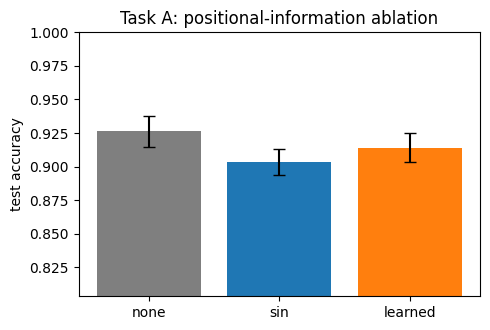

In [13]:
tf_df = pd.DataFrame(tf_runs)
tbl = tf_df.groupby("pos").agg(test_acc=("test_acc", mean_std), macro_f1=("macro_f1", mean_std),
                               params=("params","first"), sec_per_epoch=("sec_per_epoch","mean"))
tbl.index = ["Transformer (pos=" + i + ")" for i in tbl.index]
p1 = pd.read_csv(RESULTS_CSV); p1 = p1[(p1.problem == "P1") & p1.model.str.endswith("-HAR") & ~p1.notes.astype(str).str.contains("sweep")]
if len(p1):
    best_p1 = p1.groupby("model").test_acc.mean().idxmax(); b = p1[p1.model == best_p1]
    tbl.loc[f"Best Problem 1: {best_p1}"] = [mean_std(b.test_acc), mean_std(b.macro_f1), int(b.params.iloc[0]), b.sec_per_epoch.mean()]
else:
    print("Run Problem 1 first to add its best model to this table.")
tbl.to_csv(f"{FIG}/table_taskA.csv"); display(tbl)

g = tf_df.groupby("pos").test_acc.agg(["mean","std"]).reindex(["none","sin","learned"])
plt.figure(figsize=(5, 3.4)); plt.bar(g.index, g["mean"], yerr=g["std"], capsize=4, color=["C7","C0","C1"])
plt.ylim(max(0, g["mean"].min() - 0.1), 1); plt.ylabel("test accuracy"); plt.title("Task A: positional-information ablation")
plt.tight_layout(); plt.savefig(f"{FIG}/taskA_pos_ablation.png", dpi=150); plt.show()

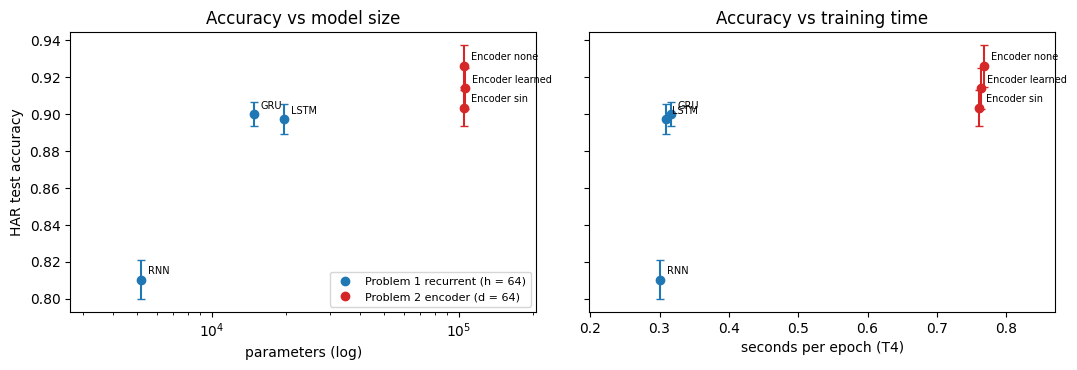

,label,acc,sd,params,spe
0,Encoder learned,0.9140,0.0110,106310,0.7630
1,Encoder none,0.9261,0.0114,105222,0.7682
2,Encoder sin,0.9034,0.0098,105222,0.7606
3,GRU,0.9001,0.0066,14790,0.3162
4,LSTM,0.8974,0.0083,19590,0.3087
5,RNN,0.8104,0.0107,5190,0.3012


In [14]:
# Task A vs Problem 1: accuracy against parameters and against training time (mean ± std over 3 seeds)
res = pd.read_csv(RESULTS_CSV)
har = res[res.model.str.contains("HAR") & ~res.notes.astype(str).str.contains("sweep")].copy()   # P1 *-HAR and P2 ENC-HAR-*
har["label"] = har.model.str.replace("ENC-HAR-", "Encoder ", regex=False).str.replace("-HAR", "", regex=False)
g = har.groupby("label").agg(acc=("test_acc", "mean"), sd=("test_acc", "std"),
                             params=("params", "first"), spe=("sec_per_epoch", "mean")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for _, r in g.iterrows():
    col = "C3" if r.label.startswith("Encoder") else "C0"
    for a, xcol in zip(ax, ["params", "spe"]):
        a.errorbar(r[xcol], r.acc, yerr=r.sd, fmt="o", color=col, capsize=3)
        a.annotate(r.label, (r[xcol], r.acc), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax[0].set_xscale("log"); ax[0].set_xlabel("parameters (log)"); ax[0].set_ylabel("HAR test accuracy")
ax[1].set_xlabel("seconds per epoch (T4)")
for a in ax: a.margins(x=0.22)
ax[0].set_title("Accuracy vs model size"); ax[1].set_title("Accuracy vs training time")
ax[0].legend([plt.Line2D([], [], color="C0", marker="o", ls=""), plt.Line2D([], [], color="C3", marker="o", ls="")],
             ["Problem 1 recurrent (h = 64)", "Problem 2 encoder (d = 64)"], fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG}/taskA_vs_problem1.png", dpi=150); plt.show()
g.round(4)

## Task 4 — Task B: character-level causal language model (10)
Context 128, d = 128, 4 heads, 4 layers; first 90 % train / last 10 % validation, no shuffling of the split.

In [15]:
TXT = os.path.join(DATA, "tinyshakespeare.txt")
if not os.path.exists(TXT):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", TXT)
text = open(TXT, encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ix: "".join(itos[i] for i in ix)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
print(f"{len(text):,} characters, vocabulary {V}")
assert V == 65 and decode(encode("To be, or not")) == "To be, or not"

def get_batch(split, gen, ctx=CTX, batch=BATCH_LM):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - ctx - 1, (batch,), generator=gen)
    x = torch.stack([src[i:i + ctx] for i in ix]); y = torch.stack([src[i + 1:i + ctx + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

1,115,394 characters, vocabulary 65


In [16]:
class CharTransformer(nn.Module):
    def __init__(self, d=D_MODEL, heads=HEADS, layers=LAYERS, ctx=CTX, causal=True, dropout=DROPOUT):
        super().__init__()
        self.ctx, self.causal = ctx, causal
        self.tok = nn.Embedding(V, d)
        self.enc = Encoder(d, heads, layers, max_len=ctx, pos="sin", dropout=dropout)
        self.head = nn.Linear(d, V)
        self.register_buffer("mask", torch.tril(torch.ones(ctx, ctx, dtype=torch.bool)))
    def forward(self, idx):                         # idx: (B, T) -> logits (B, T, V)
        T = idx.size(1)
        return self.head(self.enc(self.tok(idx), self.mask[:T, :T] if self.causal else None))

    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=TOP_K, gen=None):
        self.eval()
        for _ in range(n):
            logits = self(idx[:, -self.ctx:])[:, -1] / temperature
            v, _ = torch.topk(logits, top_k); logits[logits < v[:, [-1]]] = -float("inf")
            nxt = torch.multinomial(F.softmax(logits, -1).cpu(), 1, generator=gen).to(DEVICE)
            idx = torch.cat([idx, nxt], 1)
        return idx

@torch.no_grad()
def estimate(model, gen, batches=EVAL_BATCHES):
    model.eval(); out = {}
    for split in ["train", "val"]:
        L = [F.cross_entropy(model(x).flatten(0, 1), y.flatten()).item() for x, y in (get_batch(split, gen) for _ in range(batches))]
        out[split] = float(np.mean(L))
    model.train(); return out

def train_lm(name, iters, seed=SEEDS[0], log=True, **kw):
    set_seed(seed); gen = torch.Generator().manual_seed(seed); egen = torch.Generator().manual_seed(1234)
    model = CharTransformer(**kw).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=iters, pct_start=0.05)
    curve, t0 = [], time.time()
    for it in range(1, iters + 1):
        x, y = get_batch("train", gen)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % EVAL_EVERY == 0 or it == iters:
            e = estimate(model, egen); curve.append({"iter": it, "train_batch": loss.item(), **e})
            print(f"[{name}] iter {it}: train {e['train']:.3f}  val {e['val']:.3f}")
    secs = time.time() - t0; curve = pd.DataFrame(curve); val = curve.val.iloc[-1]
    if log:
        log_result(problem="P2", model=name, seed=seed, seq_len=kw.get("ctx", CTX), params=n_params(model),
                   val_loss_nats=val, bits_per_char=val / math.log(2),
                   notes=f"iters={iters} d={kw.get('d', D_MODEL)} heads={kw.get('heads', HEADS)} layers={kw.get('layers', LAYERS)} causal={kw.get('causal', True)} train_secs={secs:.0f}")
    return model, curve

lm, lm_curve = train_lm("CharTransformer", LM_ITERS)
val = lm_curve.val.iloc[-1]
print(f"validation loss {val:.4f} nats = {val / math.log(2):.4f} bits/char   (uniform: ln 65 = {math.log(65):.2f})")

[CharTransformer] iter 250: train 2.318  val 2.333


[CharTransformer] iter 500: train 1.957  val 2.039


[CharTransformer] iter 750: train 1.765  val 1.902


[CharTransformer] iter 1000: train 1.659  val 1.808


[CharTransformer] iter 1250: train 1.583  val 1.759


[CharTransformer] iter 1500: train 1.538  val 1.720


... (10 outputs left out)

[CharTransformer] iter 4250: train 1.360  val 1.577


[CharTransformer] iter 4500: train 1.353  val 1.574


[CharTransformer] iter 4750: train 1.359  val 1.568


[CharTransformer] iter 5000: train 1.357  val 1.570
validation loss 1.5697 nats = 2.2646 bits/char   (uniform: ln 65 = 4.17)


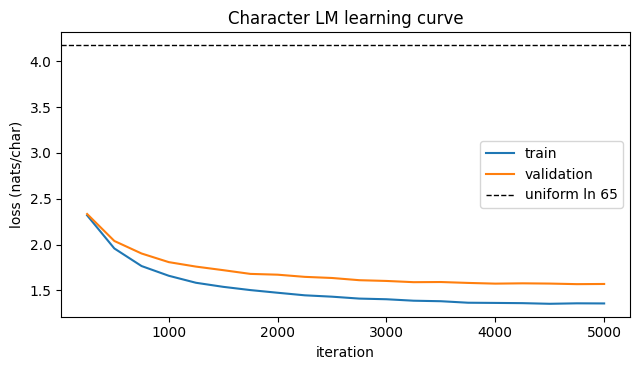

In [17]:
plt.figure(figsize=(6.5, 3.8))
plt.plot(lm_curve.iter, lm_curve.train, label="train"); plt.plot(lm_curve.iter, lm_curve.val, label="validation")
plt.axhline(math.log(V), ls="--", c="k", lw=1, label="uniform ln 65")
plt.xlabel("iteration"); plt.ylabel("loss (nats/char)"); plt.title("Character LM learning curve"); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/lm_learning_curve.png", dpi=150); plt.show()

In [18]:
import re
gen = torch.Generator().manual_seed(SEEDS[0])
start = torch.tensor([encode("\n")], device=DEVICE)
with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for temp in [0.2, 0.8, 1.5]:
        s = decode(lm.generate(start, 500, temperature=temp, gen=gen)[0, 1:].tolist())
        assert len(s) == 500
        f.write(f"===== temperature {temp} (top-k {TOP_K}, 500 characters) =====\n{s}\n\n")
        print(f"===== temperature {temp} =====\n{s}\n")
# simple numbers behind the description of the three temperatures
train_words = set(re.findall(r"[a-z']+", text[:n].lower()))
def sample_stats(s):
    words = re.findall(r"[a-z']+", s.lower()); grams = [s[i:i + 4] for i in range(len(s) - 3)]
    return {"distinct characters": len(set(s)), "words": len(words),
            "% words seen in training text": round(100 * np.mean([w_ in train_words for w_ in words]), 1) if words else 0,
            "% repeated 4-grams": round(100 * (1 - len(set(grams)) / len(grams)), 1)}
import re
samples = re.split(r"===== temperature [\d.]+[^\n]*=====\n", open("generated_samples.txt", encoding="utf-8").read())[1:]
print("Sample statistics (higher repetition = more conservative; fewer real words = noisier):")
display(pd.DataFrame({f"T = {t}": sample_stats(s_.rstrip("\n")) for t, s_ in zip([0.2, 0.8, 1.5], samples)}))

===== temperature 0.2 =====


AUTOLYCUS:
What thou art the sent of the strange of the country's son,
That when he would have stands the rest of the strike
That when I have so see the send of the country
That which with the send of the compless of my heart,
And the country to the country of the country
And the people of the many fair the world of my soul,
And the country of the fair of the man,
That the send of the many of the courts of the world.

CORIOLANUS:
I will not to the courted of the world of his soul,
And the triv



===== temperature 0.8 =====

The counter to much a villains of the world:
What, were is so the hath stop'd with made myself,
And, my body last hath heart of this men
When impress he wound was the part to fellows.

KING EDWARD IV:
Would though art well, his father, good accused
A scaring as as we not need of the country
To the duke, my lord, why, madam, I do love a broad.

KING RICHARD III:
You didle, then have make so bark her must
To speak on like thee. Come, thou shalt steel
Tender down, I that it is sitely and that.

GL



===== temperature 1.5 =====
I am the deserve, I'll shape'd.

VOLUMNIA:
Blunt-leavic,
Even so, let him love to civer,
Her about take.

Things Citizen:
Peomfes them, that? foo hou by by into a kat
And of ill use, misscrett, my miscort by lies:
Tainn threavens' note truth flumit?
Is witne: place: as we knees I hast
how shouldst, sins, drunkihgh to myself:-'

Vound Senio! I'll so the gitiGhfure faction?
Madar, for heven
Mets bleish: can, that like twere scepturable:'
Duke was
If I?' young like it.

Nurse:
Good-men:
It our pati

Sample statistics (higher repetition = more conservative; fewer real words = noisier):


,T = 0.2,T = 0.8,T = 1.5
distinct characters,39.0,43.0,49.0
words,104.0,101.0,92.0
% words seen in training text,98.1,95.0,73.9
% repeated 4-grams,49.1,11.1,3.6


*Describe the three samples in the report (repetition at 0.2, plausibility at 0.8, noise at 1.5 — whatever you actually see).*

## Task 5 — Analysis and ablations (10)
### 5(a) Attention heatmaps of two heads on one sentence

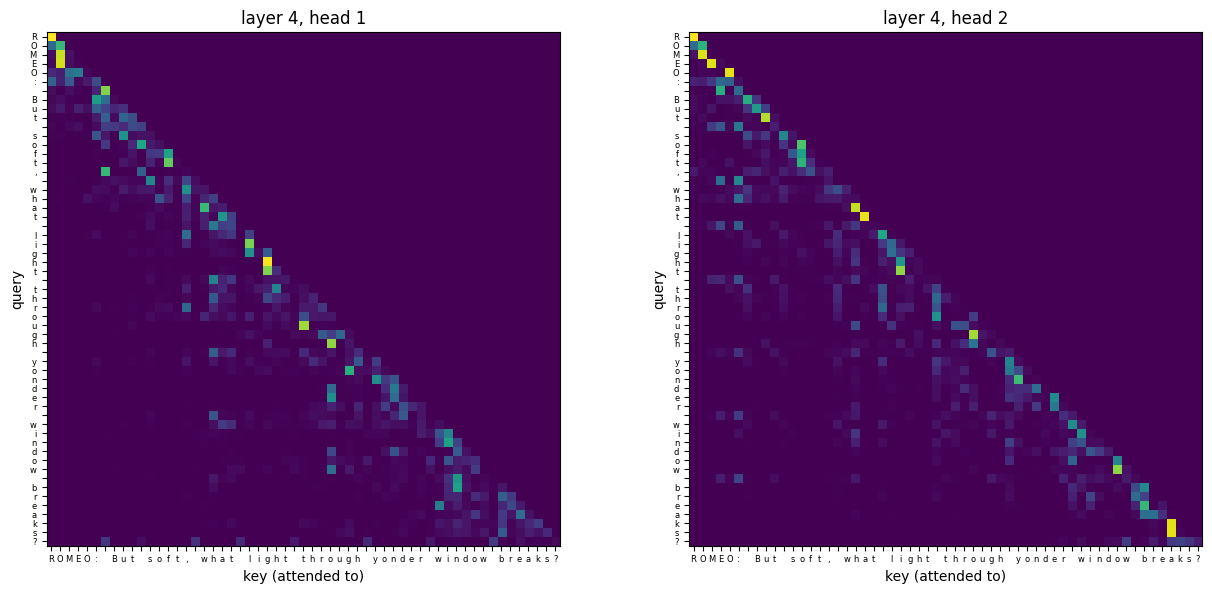

Layer 4 attention summary on: 'ROMEO: But soft, what light through yonder window breaks?'


,mean distance attended (chars),% on the same char,% on the previous char,% on spaces
head,,,,
1,5.04,13.39,20.02,10.38
2,5.35,11.61,27.57,22.59
3,6.35,12.72,18.69,7.44
4,4.43,17.38,31.12,27.69


In [19]:
SENTENCE = "ROMEO: But soft, what light through yonder window breaks?"   # any line you like
LAYER, HEADS_SHOWN = LAYERS - 1, (0, 1)
lm.eval()
with torch.no_grad(): lm(torch.tensor([encode(SENTENCE)], device=DEVICE))
A = lm.enc.blocks[LAYER].attn.last_attn[0].cpu()           # (H, T, T)
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, h in zip(ax, HEADS_SHOWN):
    a.imshow(A[h], cmap="viridis"); a.set_title(f"layer {LAYER + 1}, head {h + 1}")
    a.set_xticks(range(len(SENTENCE))); a.set_xticklabels(list(SENTENCE), fontsize=6)
    a.set_yticks(range(len(SENTENCE))); a.set_yticklabels(list(SENTENCE), fontsize=6)
    a.set_xlabel("key (attended to)"); a.set_ylabel("query")
plt.tight_layout(); plt.savefig(f"{FIG}/attention_heatmaps.png", dpi=150); plt.show()
# numbers behind the interpretation of each head
Tn = len(SENTENCE); qi, kj = np.meshgrid(np.arange(Tn), np.arange(Tn), indexing="ij")
space = np.array([ch == " " for ch in SENTENCE])
rows = []
for h in range(A.shape[0]):
    Wh = A[h].numpy()
    rows.append({"head": h + 1, "mean distance attended (chars)": (Wh * (qi - kj)).sum(1).mean(),
                 "% on the same char": 100 * np.diag(Wh).mean(), "% on the previous char": 100 * np.diag(Wh, -1).mean(),
                 "% on spaces": 100 * Wh[:, space].sum(1).mean()})
print(f"Layer {LAYER + 1} attention summary on: {SENTENCE!r}")
display(pd.DataFrame(rows).set_index("head").astype(float).round(2))

### 5(b) Heads = 1, 4, 8 at fixed d  ·  5(c) causal mask removed
Each ablation run uses the same shorter budget (`ABL_ITERS`), so the three head counts are compared fairly with each other.

[CharTransformer-heads1] iter 250: train 2.173  val 2.200


[CharTransformer-heads1] iter 500: train 1.888  val 1.990


[CharTransformer-heads1] iter 750: train 1.745  val 1.890


[CharTransformer-heads1] iter 1000: train 1.686  val 1.842


[CharTransformer-heads1] iter 1250: train 1.648  val 1.807


[CharTransformer-heads1] iter 1500: train 1.648  val 1.810


... (15 outputs left out)

[CharTransformer-nomask] iter 1000: train 0.020  val 0.021


[CharTransformer-nomask] iter 1250: train 0.020  val 0.020


[CharTransformer-nomask] iter 1500: train 0.020  val 0.020


,val_loss_nats,bits_per_char
heads=1,1.810271,2.611668
heads=4,1.810009,2.611291
heads=8,1.825955,2.634296


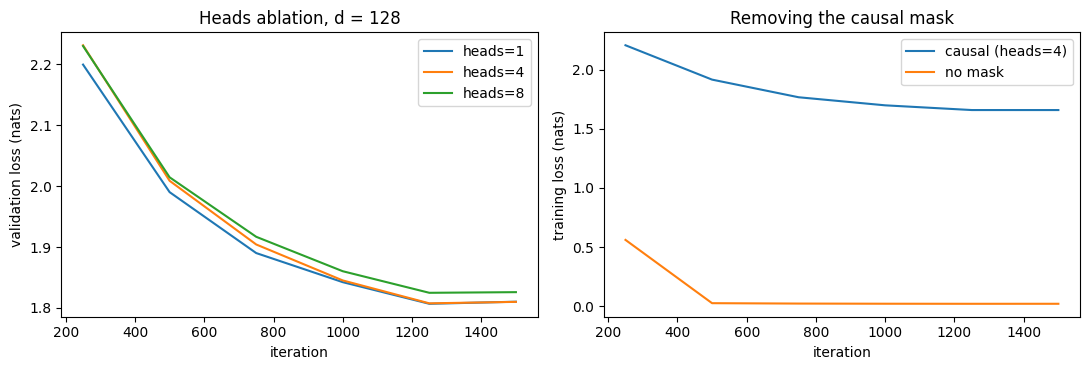

No-mask model, temperature 0.8:
 






















































































































































































s




















































































































Ablations (1500 iterations each, seed 0):


,final train loss,final val loss,val bits/char
heads=1,1.6484,1.8103,2.6117
heads=4,1.6589,1.8100,2.6113
heads=8,1.6687,1.8260,2.6343
no causal mask,0.0197,0.0196,0.0282


Final training loss: no causal mask 0.020 nats vs 1.659 nats with the mask (same budget).
No-mask sample (T=0.8): 299/300 characters are newlines, 2 distinct characters | masked model's T=0.8 sample: 18 newlines, 43 distinct characters


In [20]:
abl_curves = {}
for h in [1, 4, 8]:
    _, abl_curves[f"heads={h}"] = train_lm(f"CharTransformer-heads{h}", ABL_ITERS, heads=h)
nomask_model, abl_curves["no causal mask"] = train_lm("CharTransformer-nomask", ABL_ITERS, causal=False)

heads_tbl = pd.DataFrame({k: {"val_loss_nats": c.val.iloc[-1], "bits_per_char": c.val.iloc[-1] / math.log(2)}
                          for k, c in abl_curves.items() if k.startswith("heads")}).T
heads_tbl.to_csv(f"{FIG}/table_heads.csv"); display(heads_tbl)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k in ["heads=1", "heads=4", "heads=8"]: ax[0].plot(abl_curves[k].iter, abl_curves[k].val, label=k)
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("validation loss (nats)"); ax[0].set_title(f"Heads ablation, d = {D_MODEL}"); ax[0].legend()
ax[1].plot(abl_curves["heads=4"].iter, abl_curves["heads=4"].train, label="causal (heads=4)")
ax[1].plot(abl_curves["no causal mask"].iter, abl_curves["no causal mask"].train, label="no mask")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("training loss (nats)"); ax[1].set_title("Removing the causal mask"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/heads_and_nomask.png", dpi=150); plt.show()

gen = torch.Generator().manual_seed(SEEDS[0])
nomask_sample = decode(nomask_model.generate(start, 300, temperature=0.8, gen=gen)[0, 1:].tolist())
print("No-mask model, temperature 0.8:\n", nomask_sample)
with open(f"{FIG}/nomask_sample.txt", "w", encoding="utf-8") as f: f.write(nomask_sample)
summ = pd.DataFrame({k_: {"final train loss": c_.train.iloc[-1], "final val loss": c_.val.iloc[-1],
                          "val bits/char": c_.val.iloc[-1] / math.log(2)} for k_, c_ in abl_curves.items()}).T
print(f"Ablations ({ABL_ITERS} iterations each, seed {SEEDS[0]}):"); display(summ.round(4))
print(f"Final training loss: no causal mask {summ.loc['no causal mask', 'final train loss']:.3f} nats vs "
      f"{summ.loc['heads=4', 'final train loss']:.3f} nats with the mask (same budget).")
print(f"No-mask sample (T=0.8): {nomask_sample.count(chr(10))}/{len(nomask_sample)} characters are newlines, "
      f"{len(set(nomask_sample))} distinct characters | masked model's T=0.8 sample: "
      f"{samples[1].count(chr(10))} newlines, {len(set(samples[1]))} distinct characters")

### 5(d) Time and memory against context length (64, 128, 256, 512)
One forward + backward pass of the full model (batch 16), averaged over 10 steps after warm-up. Memory is peak CUDA memory (not available on CPU).

,context,model_ms_per_step,model_activation_MB,attn_ms,attn_MB,attn_matrix_MB_theory
0,64,12.698,32.578,1.224,4.505,1.0
1,128,12.822,77.634,1.206,17.017,4.0
2,256,22.270,197.947,2.286,66.063,16.0
3,512,64.696,605.948,8.765,260.251,64.0


model_ms_per_step      exponent per doubling: [0.01 0.8  1.54]
model_activation_MB    exponent per doubling: [1.25 1.35 1.61]
attn_ms                exponent per doubling: [-0.02  0.92  1.94]
attn_MB                exponent per doubling: [1.92 1.96 1.98]


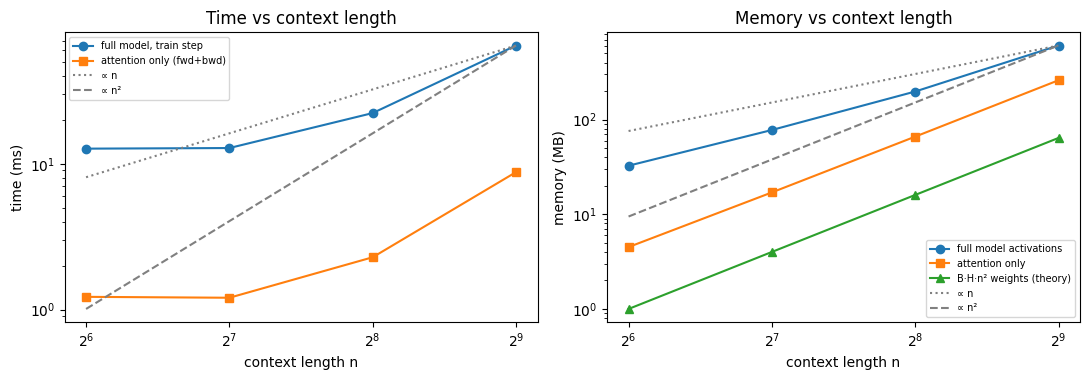

In [21]:
import gc
CTXS, B_T = [64, 128, 256, 512], 16
rows = []
for L in CTXS:
    # (1) full model, one training step (forward + backward + Adam); weights and optimiser state are excluded
    #     from the memory figure, so it measures what grows with context: activations and attention matrices
    set_seed(0); m = CharTransformer(ctx=L).to(DEVICE); opt = torch.optim.AdamW(m.parameters())
    tok = torch.randint(V, (B_T, L), device=DEVICE)                           # (B, n)
    def step():
        loss = F.cross_entropy(m(tok).flatten(0, 1), tok.flatten()); opt.zero_grad(); loss.backward(); opt.step()
    for _ in range(3): step()                                                  # warm-up also allocates Adam state
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    t0 = time.time()
    for _ in range(10): step()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    model_ms = (time.time() - t0) / 10 * 1000
    model_mb = (torch.cuda.max_memory_allocated() - base) / 2**20 if DEVICE.type == "cuda" else np.nan
    del m, opt, tok, step; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

    # (2) my scaled_dot_product_attention alone, one layer's worth: (B, H, n, d_k) = (16, 4, n, 32)
    qa, ka, va = (torch.randn(B_T, HEADS, L, D_MODEL // HEADS, device=DEVICE, requires_grad=True) for _ in range(3))
    def attn_step():
        out, _ = scaled_dot_product_attention(qa, ka, va, torch.tril(torch.ones(L, L, dtype=torch.bool, device=DEVICE)))
        out.sum().backward()
    for _ in range(3): attn_step()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    t0 = time.time()
    for _ in range(20): attn_step()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    attn_ms = (time.time() - t0) / 20 * 1000
    attn_mb = (torch.cuda.max_memory_allocated() - base) / 2**20 if DEVICE.type == "cuda" else np.nan
    del qa, ka, va; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

    rows.append({"context": L, "model_ms_per_step": model_ms, "model_activation_MB": model_mb,
                 "attn_ms": attn_ms, "attn_MB": attn_mb,
                 "attn_matrix_MB_theory": B_T * HEADS * L * L * 4 / 2**20})   # one float32 weight matrix per head
scale = pd.DataFrame(rows); scale.to_csv(f"{FIG}/table_context_scaling.csv", index=False); display(scale.round(3))

# growth exponent between successive contexts: 1 = linear, 2 = quadratic
for col in ["model_ms_per_step", "model_activation_MB", "attn_ms", "attn_MB"]:
    y = scale[col].values
    if np.isfinite(y).all():
        print(f"{col:22s} exponent per doubling:", np.round(np.log2(y[1:] / y[:-1]), 2))

Ls = scale.context.values.astype(float)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
def refs(a, y_last):
    a.plot(Ls, y_last * (Ls / Ls[-1]), ":", c="gray", label="∝ n"); a.plot(Ls, y_last * (Ls / Ls[-1]) ** 2, "--", c="gray", label="∝ n²")
ax[0].plot(Ls, scale.model_ms_per_step, "o-", label="full model, train step"); ax[0].plot(Ls, scale.attn_ms, "s-", label="attention only (fwd+bwd)")
refs(ax[0], scale.model_ms_per_step.iloc[-1]); ax[0].set_ylabel("time (ms)"); ax[0].set_title("Time vs context length")
if np.isfinite(scale.model_activation_MB).all():
    ax[1].plot(Ls, scale.model_activation_MB, "o-", label="full model activations"); ax[1].plot(Ls, scale.attn_MB, "s-", label="attention only")
    ax[1].plot(Ls, scale.attn_matrix_MB_theory, "^-", label="B·H·n² weights (theory)")
    refs(ax[1], scale.model_activation_MB.iloc[-1])
else:
    ax[1].plot(Ls, scale.attn_matrix_MB_theory, "^-", label="B·H·n² weights (theory)"); refs(ax[1], scale.attn_matrix_MB_theory.iloc[-1])
    ax[1].text(0.5, 0.1, "measured memory needs a CUDA GPU", ha="center", transform=ax[1].transAxes)
ax[1].set_ylabel("memory (MB)"); ax[1].set_title("Memory vs context length")
for a in ax:
    a.set_xscale("log", base=2); a.set_yscale("log"); a.set_xlabel("context length n"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/context_scaling.png", dpi=150); plt.show()

*Relate the growth to O(n²·d) in the report: at small n the linear (n·d²) projections and FFN dominate; the attention matrix (n² per head) takes over as n grows.*

## Optional bonus — LSTM vs Transformer on the character task

seed 0: Transformer val 1.5697 | LSTM val 1.5379


[CharTransformer] iter 250: train 2.320  val 2.328


[CharTransformer] iter 500: train 1.977  val 2.059


[CharTransformer] iter 750: train 1.773  val 1.916


[CharTransformer] iter 1000: train 1.662  val 1.821


[CharTransformer] iter 1250: train 1.578  val 1.760


... (34 outputs left out)

[CharTransformer] iter 4750: train 1.356  val 1.558


[CharTransformer] iter 5000: train 1.354  val 1.560


seed 2: Transformer val 1.5602 | LSTM val 1.5387


,val_loss_nats,bits_per_char,params,train_secs
LSTM (2 layers),1.5423 ± 0.0070,2.2251 ± 0.0101,280897,45
Transformer,1.5630 ± 0.0059,2.2549 ± 0.0085,810049,198


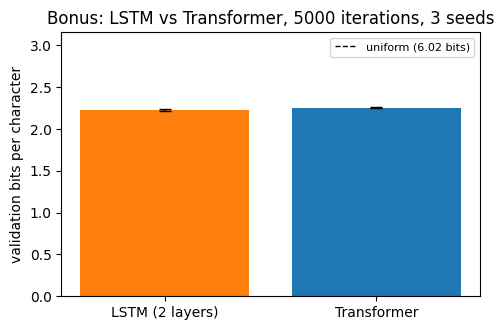

In [22]:
if RUN_BONUS:
    import re
    class CharLSTM(nn.Module):
        def __init__(self, d=D_MODEL, layers=2):
            super().__init__(); self.tok = nn.Embedding(V, d); self.rnn = nn.LSTM(d, d, layers, batch_first=True); self.head = nn.Linear(d, V)
        def forward(self, idx): return self.head(self.rnn(self.tok(idx))[0])

    def train_lstm(seed):
        set_seed(seed); gen = torch.Generator().manual_seed(seed); egen = torch.Generator().manual_seed(1234)
        m = CharLSTM().to(DEVICE); opt = torch.optim.AdamW(m.parameters(), lr=LR); t0 = time.time()
        for it in range(1, LM_ITERS + 1):
            x, y = get_batch("train", gen); loss = F.cross_entropy(m(x).flatten(0, 1), y.flatten())
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        secs = time.time() - t0; v = estimate(m, egen)["val"]
        log_result(problem="P2", model="CharLSTM-bonus", seed=seed, seq_len=CTX, params=n_params(m), val_loss_nats=v,
                   bits_per_char=v / math.log(2), notes=f"iters={LM_ITERS} train_secs={secs:.0f}")
        return dict(model="LSTM (2 layers)", seed=seed, val=v, params=n_params(m), secs=secs)

    def train_tf(seed):
        if seed == SEEDS[0]:            # already trained in Task 4: reuse its loss and logged training time
            r = pd.read_csv(RESULTS_CSV); r = r[(r.model == "CharTransformer") & (r.seed == seed)].iloc[-1]
            return dict(model="Transformer", seed=seed, val=float(val), params=int(r.params),
                        secs=float(re.search(r"train_secs=(\d+)", r.notes).group(1)))
        t0 = time.time(); m, cur = train_lm("CharTransformer", LM_ITERS, seed=seed)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        return dict(model="Transformer", seed=seed, val=float(cur.val.iloc[-1]), params=n_params(m), secs=time.time() - t0)

    runs = []
    for s in SEEDS:
        runs.append(train_tf(s)); runs.append(train_lstm(s))
        print(f"seed {s}: Transformer val {runs[-2]['val']:.4f} | LSTM val {runs[-1]['val']:.4f}")
    bdf = pd.DataFrame(runs); rows = {}
    for name, g in bdf.groupby("model"):
        rows[name] = {"val_loss_nats": mean_std(g.val), "bits_per_char": mean_std(g.val / math.log(2)),
                      "params": int(g.params.iloc[0]), "train_secs": f"{g.secs.mean():.0f}"}
    bonus_tbl = pd.DataFrame(rows).T; bonus_tbl.to_csv(f"{FIG}/table_bonus.csv"); display(bonus_tbl)

    gb = bdf.assign(bpc=bdf.val / math.log(2)).groupby("model").bpc.agg(["mean", "std"])
    plt.figure(figsize=(5, 3.4)); plt.bar(gb.index, gb["mean"], yerr=gb["std"], capsize=4, color=["C1", "C0"])
    plt.axhline(math.log(V) / math.log(2), ls="--", c="k", lw=1, label="uniform (6.02 bits)")
    plt.ylabel("validation bits per character"); plt.title(f"Bonus: LSTM vs Transformer, {LM_ITERS} iterations, 3 seeds")
    plt.ylim(0, max(gb["mean"]) * 1.4); plt.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{FIG}/bonus_lstm_vs_transformer.png", dpi=150); plt.show()